# Deep Network Development — Homework prep in ONE notebook (Practice weeks 1–8)

**How to use (tonight, ~3–4 h):** go top to bottom. Every lesson has:
1. **Explanation**: what it is, the key functions and the traps
2. **Worked example**: code with output. Run it and read the comments.
3. **🏋️ Practice**: write the code yourself. The checker below prints ✅ or ❌.

All examples use **different data** from the homework, so you learn the method and then apply it tomorrow.

| # | Lesson | From | Homework task | Time |
|---|---|---|---|---|
| 1 | Python essentials (strings, NaN, generators, classes) | W1–2, W8 | A, D | 10 min |
| 2 | Text → NumPy array with NaN | W6, W7 | **A** | 15 min |
| 3 | Missing values: count, flag columns, fill | W6, W8 | **B** | 15 min |
| 4 | NumPy toolbox (masks, argmax, axis, broadcasting, fancy indexing) | W3–W5 | G, I, coding test | 30 min |
| 5 | Shuffle + train/val/test split | W7, W8 | **C** | 10 min |
| 6 | Feature scaling (train statistics only) | W5, W8 | coding test (optional in HW) | 10 min |
| 7 | PyTorch tensors | W7 | D–I | 10 min |
| 8 | Batching: generator, `Dataset`, `DataLoader` | W8 | **D**, **G** | 20 min |
| 9 | `nn.Module` models + parameter count | W7 | **E**, **H** | 15 min |
| 10 | Full training loop (regression, MSE, plot, test loss) | W7, W8 | **F** | 25 min |
| 11 | Category labels from rules + dropping columns | W3–W4 | **G** | 15 min |
| 12 | Multi-class: logits, `CrossEntropyLoss`, accuracy | lecture | **H**, **I** | 15 min |
| 13 | Early stopping + restoring the best weights | lecture | **I** | 20 min |
| 14 | Confusion matrix (NumPy) + plot | W6 | **I** | 15 min |
| 15 | **Homework playbook A–I** (what each tester checks, traps) | — | all | 10 min |
| 16 | Cheat sheet for the coding test | — | — | read |

In [1]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
torch.manual_seed(0)

def check(name, test):
    # Runs test() -> bool. Prints ✅ / ❌ / ⏳. Never crashes the notebook.
    g = test.__globals__
    if any(n in g and g[n] is None for n in test.__code__.co_names):   # a variable you still have to fill is None
        print(f"⏳ {name}: not done yet")
        return
    try:
        ok = bool(test())
    except NotImplementedError:
        print(f"⏳ {name}: not done yet")
        return
    except Exception as e:
        if 'NoneType' in str(e) or isinstance(e, NameError):
            print(f"⏳ {name}: not done yet")
        else:
            print(f"❌ {name}: error -> {type(e).__name__}: {e}")
        return
    print(f"✅ {name}: passed" if ok else f"❌ {name}: wrong result")

---
## Lesson 1: Python essentials you will actually use

**Strings**
- `s.strip()` removes spaces, `\n` and `\r` at both ends. `s.split(';')` gives a list of fields. An empty field becomes `''`.
- `float('3.5')` → `3.5`. `float('nan')` (or `np.nan`) marks a **missing value**.
- **NaN is never equal to anything, not even itself**: `np.nan == np.nan` is `False`. Always test with `np.isnan(...)`.

**Generators** (`yield`): a function that hands out values one at a time. `for` asks for the next value until the function ends. This is the easiest way to write a batch iterator.

**Classes** (`__init__`, `super().__init__()`, overriding methods) are needed because every PyTorch model and dataset **is a subclass**.

In [2]:
line = " 3;;7.5;\r"
fields = line.strip().split(';')            # strip removes the '\r' and the leading space
print(fields)                               # ['3', '', '7.5', '']
vals = [np.nan if f == '' else float(f) for f in fields]
print(vals)                                 # [3.0, nan, 7.5, nan]

x = float('nan')
print("nan == nan ->", x == x, "| np.isnan ->", np.isnan(x))   # False | True

# generator: yields one chunk at a time
def chunks(seq, size):
    for start in range(0, len(seq), size):  # 0, size, 2*size, ...
        yield seq[start:start + size]       # last chunk may be shorter

print(list(chunks(list(range(7)), 3)))      # [[0, 1, 2], [3, 4, 5], [6]]

# class + inheritance + super()
class Animal:
    def __init__(self, name):
        self.name = name
    def speak(self):
        return "..."

class Dog(Animal):
    def __init__(self, name, breed):
        super().__init__(name)              # let the parent set self.name
        self.breed = breed
    def speak(self):                        # override
        return f"{self.name} ({self.breed}) says woof"

print(Dog("Rex", "lab").speak())

['3', '', '7.5', '']
[3.0, nan, 7.5, nan]
nan == nan -> False | np.isnan -> True
[[0, 1, 2], [3, 4, 5], [6]]
Rex (lab) says woof


#### 🏋️ Practice 1.1: paired batch generator

Write a generator `paired_chunks(xs, ys, size)` that yields tuples `(xs_chunk, ys_chunk)` of the same positions.
Example: `list(paired_chunks([1,2,3,4,5], ['a','b','c','d','e'], 2))` → `[([1,2],['a','b']), ([3,4],['c','d']), ([5],['e'])]`

In [3]:
# ===== YOUR CODE BELOW =====
def paired_chunks(xs, ys, size):
    raise NotImplementedError
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("1.1", lambda: list(paired_chunks([1,2,3,4,5], ['a','b','c','d','e'], 2))
      == [([1,2],['a','b']), ([3,4],['c','d']), ([5],['e'])])

⏳ 1.1: not done yet


---
## Lesson 2: Text → NumPy array with NaN  (→ homework **A**)

A data file read into one long string looks like this: a **header line**, then one line per sample, with values separated by a separator (`,` or `;`).

**Method:**
1. `text.split('\n')` gives the lines. **Drop the header** (`lines[0]`) and **drop empty lines**. The file usually ends with `\n`, so the last element is `''`.
2. For each line: `line.strip().split(sep)` gives the fields.
3. Each field: `''` → `np.nan`, otherwise `float(field)`.
4. `np.array(rows, dtype=np.float32)` gives shape `(n_samples, n_columns)`.

**Shortcut that also works:** `np.genfromtxt(io.StringIO(text), delimiter=';', skip_header=1, dtype=np.float32)`. It turns empty fields into `nan` automatically.

**Traps:** forgetting the header gives `ValueError: could not convert string to float`. Forgetting the empty last line gives an empty row, which makes `np.array` fail or creates an object array. Leaving out `dtype=np.float32` gives float64.

In [4]:
weather_text = "day,temp,humidity,wind,rain\n1,21.5,,3.2,0\n2,,55,4.1,1\n3,18.0,60,,0\n4,25.1,40,2.0,\n"
print(repr(weather_text[:60]), '...')

def parse_text(text, sep):
    lines = text.split('\n')
    print("first line (header):", lines[0], "| last line:", repr(lines[-1]))
    rows = []
    for line in lines[1:]:                    # skip header
        if line.strip() == '':                # skip empty lines (end of file)
            continue
        fields = line.strip().split(sep)
        rows.append([np.nan if f == '' else float(f) for f in fields])
    return np.array(rows, dtype=np.float32)

weather = parse_text(weather_text, ',')
print(weather)
print(weather.shape, weather.dtype)                        # (4, 5) float32
print("NaN positions (row, col):\n", np.argwhere(np.isnan(weather)))

# the shortcut gives the same result:
import io
weather2 = np.genfromtxt(io.StringIO(weather_text), delimiter=',', skip_header=1, dtype=np.float32)
print("same as shortcut:", np.array_equal(weather, weather2, equal_nan=True))

'day,temp,humidity,wind,rain\n1,21.5,,3.2,0\n2,,55,4.1,1\n3,18.0' ...
first line (header): day,temp,humidity,wind,rain | last line: ''
[[ 1.  21.5  nan  3.2  0. ]
 [ 2.   nan 55.   4.1  1. ]
 [ 3.  18.  60.   nan  0. ]
 [ 4.  25.1 40.   2.   nan]]
(4, 5) float32
NaN positions (row, col):
 [[0 2]
 [1 1]
 [2 3]
 [3 4]]
same as shortcut: True


#### 🏋️ Practice 2.1: parse a semicolon file

Parse `farm_text` into `farm` with dtype **float32**, shape `(4, 5)`, and NaN for empty fields. Note the `;;` and the `;` at the end of a line.
Expected NaN positions: `[[0,3],[1,1],[1,4],[2,2]]`.

In [5]:
farm_text = "farm;cows;milk;area;owner_age\n0;12;340.5;;45\n1;;210.0;30.5;\n2;7;;12.0;61\n3;20;500.25;44.0;38\n"

# ===== YOUR CODE BELOW =====
farm = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("2.1 shape/dtype", lambda: farm.shape == (4, 5) and farm.dtype == np.float32)
check("2.1 NaN positions", lambda: np.array_equal(np.argwhere(np.isnan(farm)), [[0,3],[1,1],[1,4],[2,2]]))
check("2.1 values", lambda: np.isclose(np.nansum(farm), 1326.25))

⏳ 2.1 shape/dtype: not done yet
⏳ 2.1 NaN positions: not done yet
⏳ 2.1 values: not done yet


---
## Lesson 3: Missing values: inspect, flag, fill  (→ homework **B**)

**Inspect** (with `mask = np.isnan(arr)`, a bool array of the same shape):
- total: `np.count_nonzero(mask)`
- per column: `np.count_nonzero(mask, axis=0)` · rows that have any NaN: `np.any(mask, axis=1)`
- which columns have NaN: `np.where(np.any(mask, axis=0))[0]`
- NaN-ignoring statistics: `np.nanmean`, `np.nanmin`, `np.nanmax`, `np.nansum`

**Ways to handle missing values** (Week 8):
- Replace them with 0, the column mean or the median: `arr[mask] = 0.` or `np.where(mask, col_mean, arr)`.
- **Add a "flag" column** for each affected variable: **1 = value present, 0 = missing**. The network can then learn that "0 here means missing", not a real 0.

**Building flag columns, vectorized:**
```python
cols = [1, 3]
flags = (~np.isnan(arr[:, cols])).astype(np.float32)   # (n, 2): 1 valid, 0 missing
new = np.concatenate([arr, flags], axis=1)             # appended AFTER the original columns
new[np.isnan(new)] = 0.                                # finally fill the NaNs
```
**Traps:** the order of the flag columns must follow `cols`. Use `astype(np.float32)`, because int64 flags would upcast the whole array to float64. Do the fill **after** computing the flags, otherwise every flag is 1.

In [6]:
print(weather)
mask = np.isnan(weather)
print("total NaN:", np.count_nonzero(mask))
print("NaN per column:", np.count_nonzero(mask, axis=0))
print("rows with any NaN:", np.count_nonzero(np.any(mask, axis=1)))
print("columns with NaN:", np.where(np.any(mask, axis=0))[0])
print("column means ignoring NaN:", np.nanmean(weather, axis=0))

# Option 1: fill with the column mean (broadcasting: (4,5) vs (5,))
filled_mean = np.where(mask, np.nanmean(weather, axis=0), weather)
print("filled with means:\n", filled_mean)

# Option 2: flag columns + fill with 0
cols_with_nan = [1, 3, 4]
flags = (~np.isnan(weather[:, cols_with_nan])).astype(np.float32)   # (4, 3)
weather_full = np.concatenate([weather, flags], axis=1)             # (4, 8)
weather_full[np.isnan(weather_full)] = 0.
print("with flags:\n", weather_full, weather_full.shape, weather_full.dtype)

[[ 1.  21.5  nan  3.2  0. ]
 [ 2.   nan 55.   4.1  1. ]
 [ 3.  18.  60.   nan  0. ]
 [ 4.  25.1 40.   2.   nan]]
total NaN: 4
NaN per column: [0 1 1 1 1]
rows with any NaN: 4
columns with NaN: [1 2 3 4]
column means ignoring NaN: [ 2.5   21.533 51.667  3.1    0.333]
filled with means:
 [[ 1.    21.5   51.667  3.2    0.   ]
 [ 2.    21.533 55.     4.1    1.   ]
 [ 3.    18.    60.     3.1    0.   ]
 [ 4.    25.1   40.     2.     0.333]]
with flags:
 [[ 1.  21.5  0.   3.2  0.   1.   1.   1. ]
 [ 2.   0.  55.   4.1  1.   0.   1.   1. ]
 [ 3.  18.  60.   0.   0.   1.   0.   1. ]
 [ 4.  25.1 40.   2.   0.   1.   1.   0. ]] (4, 8) float32


#### 🏋️ Practice 3.1: inspect

For `sensor`, compute: `nan_per_col` (array, NaN count of each column), `n_rows_with_nan` (int) and `nan_cols` (array of column indices that contain NaN).

In [7]:
sensor = np.array([[1., np.nan, 3., 4.],
                   [np.nan, 2., 3., np.nan],
                   [5., 6., 7., 8.],
                   [np.nan, 1., 2., 3.]], dtype=np.float32)

# ===== YOUR CODE BELOW =====
nan_per_col = None
n_rows_with_nan = None
nan_cols = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("3.1a", lambda: np.array_equal(nan_per_col, [2, 1, 0, 1]))
check("3.1b", lambda: n_rows_with_nan == 3)
check("3.1c", lambda: np.array_equal(nan_cols, [0, 1, 3]))

⏳ 3.1a: not done yet
⏳ 3.1b: not done yet
⏳ 3.1c: not done yet


#### 🏋️ Practice 3.2: flag columns + fill

Create `sensor_full`: the original 4 columns, then flag columns for columns **0 and 3** (in that order, 1 = valid, 0 = missing), then replace all NaN with 0.
Expected shape `(4, 6)`, dtype float32. Don't modify `sensor` itself.

In [8]:
# ===== YOUR CODE BELOW =====
sensor_full = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("3.2 shape/dtype", lambda: sensor_full.shape == (4, 6) and sensor_full.dtype == np.float32)
check("3.2 flags", lambda: np.array_equal(sensor_full[:, 4:], [[1,1],[0,0],[1,1],[0,1]]))
check("3.2 no NaN + originals kept", lambda: not np.isnan(sensor_full).any() and np.isclose(sensor_full[:, :4].sum(), np.nansum(sensor)))
check("3.2 sensor untouched", lambda: sensor_full is not None and np.count_nonzero(np.isnan(sensor)) == 4)

⏳ 3.2 shape/dtype: not done yet
⏳ 3.2 flags: not done yet
⏳ 3.2 no NaN + originals kept: not done yet
⏳ 3.2 sensor untouched: not done yet


---
## Lesson 4: NumPy toolbox (Weeks 3–5, the core of the coding test)

| Need | Tool | Shape effect |
|---|---|---|
| element / row / column | `a[i, j]`, `a[i]`, `a[:, j]` | int removes an axis |
| keep the axis | `a[:, j:j+1]`, `a[:, [j]]`, `a[:, j, None]` | `(n,1)` |
| condition | `mask = a > 5`; combine with `&`, `\|`, `~` (with **parentheses**) | mask indexing → **1-D** |
| reduce | `np.sum/mean/max/min(a, axis=k)` | removes axis `k`; `keepdims=True` keeps it as size 1 |
| position of max/min | `np.argmax(a, axis=k)` | indices (+1 for "month numbers") |
| global max position | `np.unravel_index(np.argmax(a), a.shape)` | tuple `(row, col)` |
| per-row column choice | `a[np.arange(n), col_idx]` | `(n,)`; paired indices pick **elements** |
| broadcasting | `(n,m) op (m,)` works; `(n,m) op (n,)` needs `[:, None]` | |
| if/else per element | `np.where(cond, x, y)` | same shape |
| one-hot | `np.eye(k)[labels]` | `(n, k)` |
| counts of ints | `np.bincount(ints, minlength=k)`, `np.unique(a, return_counts=True)` | |
| sort / order | `np.sort`, `np.argsort` (NaN goes to the **end**) | |
| scale per row/col | `(a - a.min(axis, keepdims=True)) / (a.max(...) - a.min(...))` | |

**Efficient = vectorized:** no Python loop over the elements.

In [9]:
sales = np.array([[30, 55, 20, 70, 45, 60],      # store 0
                  [80, 10, 90, 15, 40, 25],      # store 1
                  [50, 50, 65, 30, 20, 95],      # store 2
                  [10, 20, 30, 40, 50, 60]])     # store 3   shape (n_stores=4, n_weeks=6)

print("total per store       :", sales.sum(axis=1))                 # (4,)
print("best week no. per store:", np.argmax(sales, axis=1) + 1)    # +1 -> week numbers
print("weeks where store0 > 50:", np.where(sales[0] > 50)[0] + 1)
print("store1 sales in weeks where store0 > 50:", sales[1, sales[0] > 50])
print("stores with any week >= 90:", np.where(np.any(sales >= 90, axis=1))[0])
print("weeks with store0>40 AND store1<30:", np.where((sales[0] > 40) & (sales[1] < 30))[0])

r, c = np.unravel_index(np.argmax(sales), sales.shape)
print("global max at (store, week idx):", (int(r), int(c)), "value", sales[r, c])

week_choice = np.array([5, 0, 2, 3])                # one week index per store
print("chosen week per store:", sales[np.arange(4), week_choice])   # paired indexing -> (4,)

share = sales / sales.sum(axis=1, keepdims=True)    # (4,6) / (4,1) -> each row sums to 1
print("row shares sum:", share.sum(axis=1))

mn, mx = sales.min(axis=0, keepdims=True), sales.max(axis=0, keepdims=True)
print("min-max per week (column):\n", (sales - mn) / (mx - mn))

labels = np.array([2, 0, 1, 2])
print("one-hot:\n", np.eye(3, dtype=np.float32)[labels])
print("bincount:", np.bincount(labels, minlength=4))

total per store       : [280 260 310 210]
best week no. per store: [4 3 6 6]
weeks where store0 > 50: [2 4 6]
store1 sales in weeks where store0 > 50: [10 15 25]
stores with any week >= 90: [1 2]
weeks with store0>40 AND store1<30: [1 3 5]
global max at (store, week idx): (2, 5) value 95
chosen week per store: [60 80 65 40]
row shares sum: [1. 1. 1. 1.]
min-max per week (column):
 [[0.286 1.    0.    1.    0.833 0.5  ]
 [1.    0.    1.    0.    0.667 0.   ]
 [0.571 0.889 0.643 0.273 0.    1.   ]
 [0.    0.222 0.143 0.455 1.    0.5  ]]
one-hot:
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
bincount: [1 1 2 0]


#### 🏋️ Practice 4.1: worst week per store

For every store, the **week number** (1-based) of its lowest sales → `worst_week`, shape `(4,)`.

In [10]:
# ===== YOUR CODE BELOW =====
worst_week = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check('4.1', lambda: np.array_equal(worst_week, [3, 2, 5, 1]))

⏳ 4.1: not done yet


#### 🏋️ Practice 4.2: masked sum

Total sales of **store 3** in the weeks where **store 2 sold at least 50** → `s3_total` (scalar).

In [11]:
# ===== YOUR CODE BELOW =====
s3_total = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check('4.2', lambda: s3_total == 120)

⏳ 4.2: not done yet


#### 🏋️ Practice 4.3: standardize each store (row)

Subtract each row's mean and divide by the row's std, **without a loop**, using `keepdims` → `sales_std` `(4,6)`. Every row should then have mean 0 and std 1.

In [12]:
# ===== YOUR CODE BELOW =====
sales_std = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check('4.3', lambda: sales_std.shape == (4,6) and np.allclose(sales_std.mean(axis=1), 0) and np.allclose(sales_std.std(axis=1), 1))

⏳ 4.3: not done yet


#### 🏋️ Practice 4.4: value of the best week of each store

Use `np.argmax(..., axis=1)` and then **paired fancy indexing** (not `np.max`) → `best_vals` `(4,)`.

In [13]:
# ===== YOUR CODE BELOW =====
best_vals = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check('4.4', lambda: np.array_equal(best_vals, [70, 90, 95, 60]))

⏳ 4.4: not done yet


#### 🏋️ Practice 4.5: accuracy from probabilities (Week 4)

`probs` has shape `(n, k)` and `y_true` shape `(n,)`. Predicted class = argmax of each row. Compute `acc`, the ratio of correct predictions (float).

In [14]:
probs = np.array([[0.7, 0.2, 0.1], [0.1, 0.3, 0.6], [0.3, 0.4, 0.3], [0.5, 0.1, 0.4], [0.2, 0.2, 0.6]])
y_true = np.array([0, 2, 0, 0, 1])

# ===== YOUR CODE BELOW =====
acc = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check('4.5', lambda: np.isclose(acc, 0.6))

⏳ 4.5: not done yet


---
## Lesson 5: Shuffle + train / validation / test split  (→ homework **C**)

Datasets are often **ordered** (by school, date, class...). Without shuffling, the splits would have different distributions.

```python
rng = np.random.default_rng(42)            # seeded so the result is reproducible
perm = rng.permutation(n)                  # random order of 0..n-1
shuffled = arr[perm]                       # rows reordered; each row stays intact
n_train = int(n * 0.5); n_val = int(n * 0.25)
train = shuffled[:n_train]; val = shuffled[n_train:n_train+n_val]; test = shuffled[n_train+n_val:]
```
- If inputs and labels are **separate** arrays, index both with the **same** `perm`.
- `rng.shuffle(arr)` shuffles the rows **in place** (alternative).
- The test set takes "the rest", so every sample is used exactly once.

In [15]:
arr = np.arange(30).reshape(10, 3).astype(np.float32)   # 10 samples, 3 columns
rng = np.random.default_rng(42)
perm = rng.permutation(arr.shape[0])
print("perm:", perm)
shuffled = arr[perm]

n = shuffled.shape[0]
n_train, n_val = int(n * 0.6), int(n * 0.2)
train, val, test = shuffled[:n_train], shuffled[n_train:n_train + n_val], shuffled[n_train + n_val:]
print(train.shape, val.shape, test.shape)                # (6,3) (2,3) (2,3)
print("every row used once:",
      np.array_equal(np.sort(np.concatenate([train, val, test])[:, 0]), arr[:, 0]))

perm: [5 6 0 7 3 2 4 9 1 8]
(6, 3) (2, 3) (2, 3)
every row used once: True


#### 🏋️ Practice 5.1: 60 / 20 / 20 split

Shuffle the rows of `points` (column 0 is an id) using `rng`, then split into `p_train`, `p_val`, `p_test` with 60% / 20% / rest.
Expected sizes: 13, 4, 6.

In [16]:
points = np.column_stack([np.arange(23), np.random.default_rng(1).normal(size=(23, 3))]).astype(np.float32)
rng = np.random.default_rng(7)

# ===== YOUR CODE BELOW =====
p_train = p_val = p_test = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("5.1 sizes", lambda: (len(p_train), len(p_val), len(p_test)) == (13, 4, 6))
allp = lambda: np.concatenate([p_train, p_val, p_test])
check("5.1 all rows once, rows intact", lambda: p_train is not None and np.allclose(np.sort(allp()[:, 1]), np.sort(points[:, 1]))
      and np.array_equal(np.sort(allp()[:, 0]), np.arange(23)))
check("5.1 actually shuffled", lambda: p_train is not None and not np.array_equal(allp(), points))

⏳ 5.1 sizes: not done yet
⏳ 5.1 all rows once, rows intact: not done yet
⏳ 5.1 actually shuffled: not done yet


---
## Lesson 6: Feature scaling (train statistics only)  (coding test; **optional** in the homework)

Very different input ranges (e.g. absences 0–75 vs a binary 0/1) distort the loss surface, so training is slow or unstable.
- **Standardization:** `(x - mean) / std`, per **column** (`axis=0`).
- **Min-max:** `(x - min) / (max - min)`.
- **Compute the statistics on the TRAINING set only**, then apply the same numbers to val and test. The test set must stay "unseen".
- Guard against `std == 0` (a constant column): `std[std == 0] = 1`.
- Scale **inputs only**. Leave regression labels in their original units, so the MSE is in "grade²".
- ⚠️ **It doesn't always help.** I checked on the homework data: for **F**, standardizing the inputs made the test MSE *worse* (≈3.5–4, outside the tester range), because two inputs are almost equal to the target and scaling amplifies the noisy columns. **For the homework, train without scaling.**

In [17]:
rng = np.random.default_rng(0)
tr = rng.normal(loc=[5, 100, 0.5], scale=[1, 30, 0.1], size=(8, 3)).astype(np.float32)
va = rng.normal(loc=[5, 100, 0.5], scale=[1, 30, 0.1], size=(3, 3)).astype(np.float32)

mean = tr.mean(axis=0)                 # (3,)  from TRAIN only
std = tr.std(axis=0)
std[std == 0] = 1.0                    # safety for constant columns
tr_s = (tr - mean) / std               # broadcasting (8,3) - (3,)
va_s = (va - mean) / std               # SAME mean/std applied to validation
print("train mean ~0:", tr_s.mean(axis=0), " train std ~1:", tr_s.std(axis=0))
print("val (not exactly 0/1, which is expected):", va_s.mean(axis=0))

train mean ~0: [-0.  0. -0.]  train std ~1: [1. 1. 1.]
val (not exactly 0/1, which is expected): [-0.183 -0.153 -0.176]


#### 🏋️ Practice 6.1: min-max with train statistics

Min-max scale the **columns** of `tr` and `va` to [0, 1] using **train** min/max → `tr_mm`, `va_mm`.

In [18]:
# ===== YOUR CODE BELOW =====
tr_mm = va_mm = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("6.1 train in [0,1]", lambda: np.allclose(tr_mm.min(axis=0), 0) and np.allclose(tr_mm.max(axis=0), 1))
check("6.1 val uses train stats", lambda: np.allclose(va_mm, (va - tr.min(0)) / (tr.max(0) - tr.min(0))))

⏳ 6.1 train in [0,1]: not done yet
⏳ 6.1 val uses train stats: not done yet


---
## Lesson 7: PyTorch tensors

| NumPy | PyTorch |
|---|---|
| `np.array(x, dtype=np.float32)` | `torch.tensor(x, dtype=torch.float32)` (copies) |
| `axis=` | `dim=` (`axis=` also accepted) |
| `a[:, None]` | same, or `t.unsqueeze(1)` |
| `np.argmax(a, axis=1)` | `t.argmax(dim=1)` |
| `np.concatenate` | `torch.cat` |

- **Dtypes the homework checks:** inputs `torch.float32`, regression labels `torch.float32`, class labels **`torch.int64`** (= `torch.long`).
- `t.item()` turns a 1-element tensor into a Python float. Use it for `test_mse`, `test_ce`, `test_acc` and for logging.
- `t.numpy()` converts back. With autograd attached you need `t.detach().numpy()`.
- `with torch.no_grad():` → no gradient tracking (evaluation, prediction).

In [19]:
a = np.array([[1, 2], [3, 4]], dtype=np.float32)
t = torch.tensor(a, dtype=torch.float32)
labels_np = np.array([2, 0, 1])
lt = torch.tensor(labels_np, dtype=torch.int64)
print(t.dtype, t.shape, "|", lt.dtype, lt.shape)
print("unsqueeze:", lt[:, None].shape, lt.unsqueeze(1).shape)
print("argmax rows:", t.argmax(dim=1))
loss_like = (t ** 2).mean()
print("tensor:", loss_like, "-> python float:", loss_like.item(), type(loss_like.item()))
print("back to numpy:", t.numpy())

torch.float32 torch.Size([2, 2]) | torch.int64 torch.Size([3])
unsqueeze: torch.Size([3, 1]) torch.Size([3, 1])
argmax rows: tensor([1, 1])
tensor: tensor(7.5000) -> python float: 7.5 <class 'float'>
back to numpy: [[1. 2.]
 [3. 4.]]


#### 🏋️ Practice 7.1: dtypes and shapes

From `feat_np` (float64!) and `cls_np`, create `feat_t` (float32), `cls_t` (int64, shape `(5,)`) and `reg_t` = `cls_np` as **float32 with shape `(5, 1)`**.

In [20]:
feat_np = np.random.default_rng(3).normal(size=(5, 4))
cls_np = np.array([0, 2, 1, 1, 0])

# ===== YOUR CODE BELOW =====
feat_t = cls_t = reg_t = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("7.1", lambda: feat_t.dtype == torch.float32 and cls_t.dtype == torch.int64 and cls_t.shape == (5,)
      and reg_t.dtype == torch.float32 and reg_t.shape == (5, 1))

⏳ 7.1: not done yet


---
## Lesson 8: Batching: generator → `Dataset` + `DataLoader`  (→ homework **D**, **G**)

Training takes **mini-batches**. Three ways (Week 8):
1. Manual slicing inside the loop.
2. A generator (Lesson 1) that yields `(xb, yb)`.
3. **`Dataset` + `DataLoader`**, the standard way and the easiest for the homework:

```python
class MyDataset(Dataset):
    def __init__(self, inputs_np, targets_np):         # convert ONCE here
        self.x = torch.tensor(inputs_np, dtype=torch.float32)
        self.y = torch.tensor(targets_np)               # dtype comes from the numpy array
    def __len__(self):
        return self.x.shape[0]
    def __getitem__(self, idx):                         # ONE sample
        return self.x[idx], self.y[idx]

loader = DataLoader(MyDataset(X, y), batch_size=32, shuffle=True)   # shuffle -> random order every epoch
```
The `DataLoader` **stacks** the samples:
- target per sample of shape `(1,)` (from a `(n,1)` array) → batch `(B, 1)` ← **regression**
- target per sample that is a scalar (from an `(n,)` int64 array) → batch `(B,)` ← **classification**

**Selecting columns** for inputs vs labels:
- label column `k` as `(n,1)`: `arr[:, k:k+1]` or `arr[:, [k]]`
- inputs = everything except some columns: `np.delete(arr, [k1, k2], axis=1)`. This returns a copy and leaves `arr` unchanged.
- **Train/val loaders:** `shuffle=True`. **Test loader:** `shuffle=False`, to keep the order.

In [21]:
rng = np.random.default_rng(0)
table = rng.normal(size=(50, 6)).astype(np.float32)          # pretend column 5 is the target

class TabularDataset(Dataset):
    def __init__(self, inputs_np, targets_np):
        self.x = torch.tensor(inputs_np, dtype=torch.float32)
        self.y = torch.tensor(targets_np)
    def __len__(self):
        return self.x.shape[0]
    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

# --- regression style: target (n,1) float32 -> batches (B,1)
X = np.delete(table, [5], axis=1)                              # (50, 5)
y_reg = table[:, 5:6]                                          # (50, 1)
reg_loader = DataLoader(TabularDataset(X, y_reg), batch_size=8, shuffle=True)
xb, yb = next(iter(reg_loader))
print("regression batch:", xb.shape, xb.dtype, yb.shape, yb.dtype)

# --- classification style: target (n,) int64 -> batches (B,)
y_cls = (table[:, 5] > 0).astype(np.int64)                     # (50,)
cls_loader = DataLoader(TabularDataset(X, y_cls), batch_size=8, shuffle=False)
xb, yb = next(iter(cls_loader))
print("classification batch:", xb.shape, xb.dtype, yb.shape, yb.dtype)

print("number of batches:", len(reg_loader), "| last batch size:", [b[0].shape[0] for b in reg_loader][-1])

# --- the same with a generator (option 2), for comparison
def minibatches(x_t, y_t, batch_size, shuffle):
    idx = torch.randperm(x_t.shape[0]) if shuffle else torch.arange(x_t.shape[0])
    for s in range(0, x_t.shape[0], batch_size):
        b = idx[s:s + batch_size]
        yield x_t[b], y_t[b]
xb, yb = next(minibatches(torch.tensor(X), torch.tensor(y_reg), 8, True))
print("generator batch:", xb.shape, yb.shape)

regression batch: torch.Size([8, 5]) torch.float32 torch.Size([8, 1]) torch.float32
classification batch: torch.Size([8, 5]) torch.float32 torch.Size([8]) torch.int64
number of batches: 7 | last batch size: 2
generator batch: torch.Size([8, 5]) torch.Size([8, 1])


#### 🏋️ Practice 8.1: label in the middle

In `grid` (shape `(40, 7)`), **column 2** is a class label (values 0–3). Inputs are **all other columns**.
Create `grid_loader` (batch size 10, shuffled) whose batches are `(10, 6)` float32 and `(10,)` int64.
Use the `TabularDataset` class from above.

In [22]:
grid = np.random.default_rng(5).normal(size=(40, 7)).astype(np.float32)
grid[:, 2] = np.random.default_rng(6).integers(0, 4, size=40)

# ===== YOUR CODE BELOW =====
grid_loader = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
def _c81():
    xb, yb = next(iter(grid_loader))
    return (xb.shape == (10, 6) and xb.dtype == torch.float32 and yb.shape == (10,) and yb.dtype == torch.int64
            and set(yb.tolist()) <= {0, 1, 2, 3} and len(grid_loader) == 4)
check("8.1", _c81)

⏳ 8.1: not done yet


---
## Lesson 9: Models with `nn.Module`  (→ homework **E**, **H**)

```python
class MyNet(nn.Module):
    def __init__(self, n_in):
        super().__init__()                      # REQUIRED
        self.layers = nn.Sequential(
            nn.Linear(n_in, 16), nn.ReLU(),
            nn.Linear(16, 8),    nn.ReLU(),
            nn.Linear(8, n_out))                # output layer
    def forward(self, x):                       # x: (B, n_in)
        return self.layers(x)                   # (B, n_out)
```
"3 fully connected layers with 25, 25 and 1 neurons" means **three `nn.Linear`**, with the **last** one having 1 output. ReLU goes **between** them, never after the last layer.

**Parameter count:** `nn.Linear(a, b)` has `a*b + b` (weights + biases). Sum over the layers.

**What goes at the end:**
| Task | last layer | activation at the end | loss |
|---|---|---|---|
| regression | `Linear(…, 1)` | **none** | `nn.MSELoss()` |
| binary | `Linear(…, 1)` | `Sigmoid` | `nn.BCELoss()` |
| **k-class** | `Linear(…, k)` | **none** (raw *logits*) | `nn.CrossEntropyLoss()` (applies softmax internally) |

In [23]:
class RegNet(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_in, 16), nn.ReLU(),
                                    nn.Linear(16, 8), nn.ReLU(),
                                    nn.Linear(8, 1))
    def forward(self, x):
        return self.layers(x)

net = RegNet(5)
print(net)
n_params = sum(p.numel() for p in net.parameters() if p.requires_grad)
print("params:", n_params, "| by formula:", (5*16+16) + (16*8+8) + (8*1+1))
print("output shape:", net(torch.randn(4, 5)).shape)        # (4, 1)

RegNet(
  (layers): Sequential(
    (0): Linear(in_features=5, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)
params: 241 | by formula: 241
output shape: torch.Size([4, 1])


#### 🏋️ Practice 9.1: 4-class network

Define `ShopClassifier(nn.Module)`: 12 inputs → 40 → 10 → **4 classes**, with ReLU after the first two layers and nothing after the last.
Instantiate it as `shop_model`. Expected parameter count: **974**. Output for a `(5, 12)` input: `(5, 4)`.

In [24]:
# ===== YOUR CODE BELOW =====
shop_model = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("9.1 params", lambda: sum(p.numel() for p in shop_model.parameters() if p.requires_grad) == 974)
check("9.1 output", lambda: shop_model(torch.randn(5, 12)).shape == (5, 4))
check("9.1 no softmax/relu at end", lambda: isinstance(list(shop_model.modules())[-1], nn.Linear))

⏳ 9.1 params: not done yet
⏳ 9.1 output: not done yet
⏳ 9.1 no softmax/relu at end: not done yet


---
## Lesson 10: The full training loop: regression with MSE  (→ homework **F**)

**One epoch** = one full pass over the training loader, then one over the validation loader.
```
for epoch:
    model.train()
    for xb, yb in train_loader:
        optimizer.zero_grad()          # 1. clear old gradients
        pred = model(xb)               # 2. forward
        loss = loss_fn(pred, yb)       # 3. scalar loss (pred and yb must have the SAME shape, e.g. (B,1))
        loss.backward()                # 4. gradients
        optimizer.step()               # 5. update weights
    model.eval(); with torch.no_grad(): validation loss
    store train/val epoch losses -> plot afterwards
```
- **Exact epoch loss** = Σ(batch_loss × batch_size) / n_samples, because the last batch can be smaller.
- **Optimizer:** `torch.optim.Adam(model.parameters(), lr=1e-3)` is a safe default.
- **Epochs:** look at the validation curve and stop **before** it starts rising (overfitting).
- **Plot:** `plt.plot(train)`, `plt.plot(val)`, `plt.legend()`, axis labels, and `plt.ylim(...)` so the end of training is still readable.
- **Test loss:** evaluate the whole test loader once after training. Store it as a **Python float** (`.item()` / `float(...)`).
- **Showing predictions:** take one batch from the test loader, predict, and print predicted vs true values side by side.

epoch   0  train 52.015  val 66.319
epoch  30  train 17.061  val 22.244


epoch  60  train 2.263  val 2.697
epoch  90  train 1.445  val 1.795


epoch 120  train 1.104  val 1.483


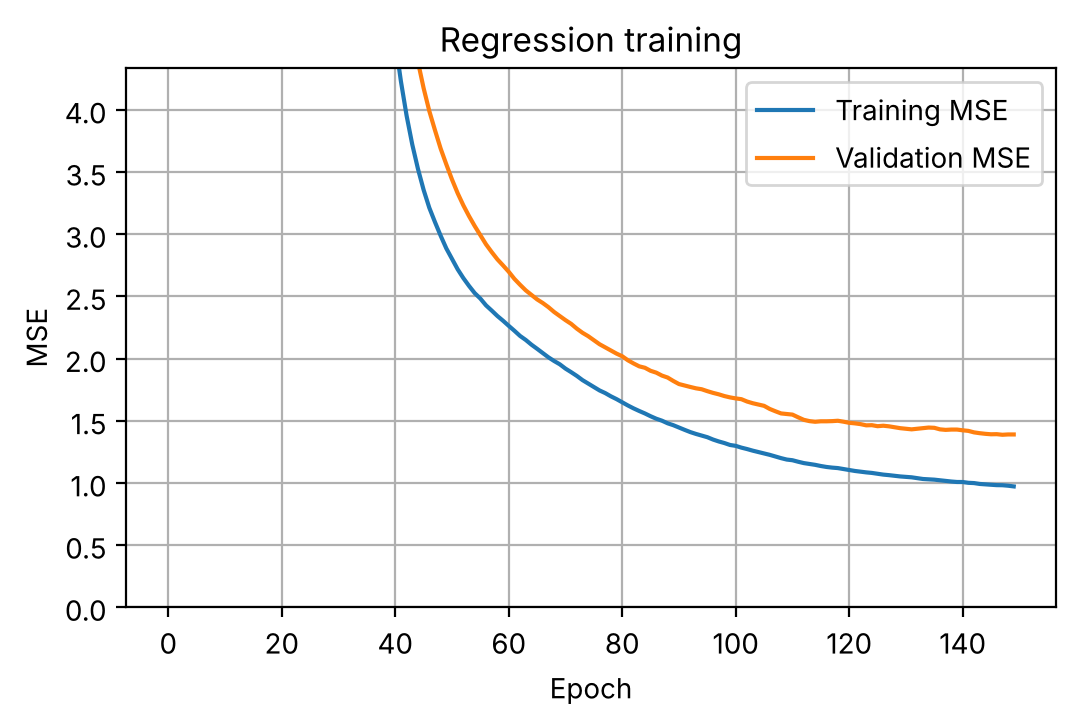

test MSE: 1.360150842666626 <class 'float'>
predicted    3.77   true    5.43
predicted    0.90   true    0.95
predicted   -1.39   true    0.02
predicted    6.09   true    5.20
predicted    3.32   true    3.33


In [25]:
torch.manual_seed(0)
# ---------- 1. synthetic regression data: 6 features with very different scales ----------
rng = np.random.default_rng(0)
n = 400
X_raw = (rng.normal(size=(n, 6)) * np.array([1, 10, 0.1, 5, 1, 50])).astype(np.float32)
true_w = np.array([2.0, 0.3, 10.0, -0.5, 1.0, 0.02], dtype=np.float32)
y_raw = (X_raw @ true_w + 5 + rng.normal(scale=1.0, size=n)).astype(np.float32)
data = np.concatenate([X_raw, y_raw[:, None]], axis=1)          # (400, 7); last column = target

# ---------- 2. shuffle + split 50/25/25 ----------
data = data[rng.permutation(n)]
a, b = int(n * 0.5), int(n * 0.25)
d_train, d_val, d_test = data[:a], data[a:a + b], data[a + b:]

# ---------- 3. inputs / target + scaling with TRAIN stats ----------
def split_xy(d):
    return d[:, :-1], d[:, -1:]                                 # target kept as (n,1)
Xtr, ytr = split_xy(d_train); Xva, yva = split_xy(d_val); Xte, yte = split_xy(d_test)
mu, sd = Xtr.mean(axis=0), Xtr.std(axis=0)
Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd

# ---------- 4. loaders ----------
train_loader = DataLoader(TabularDataset(Xtr, ytr), batch_size=32, shuffle=True)
val_loader   = DataLoader(TabularDataset(Xva, yva), batch_size=32, shuffle=True)
test_loader  = DataLoader(TabularDataset(Xte, yte), batch_size=32, shuffle=False)

# ---------- 5. model, loss, optimizer ----------
model = RegNet(6)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(model, loader, loss_fn, optimizer=None):
    # optimizer given -> train; None -> evaluate. Returns the exact mean loss over all samples.
    training = optimizer is not None
    model.train() if training else model.eval()
    total, count = 0.0, 0
    for xb, yb in loader:
        with torch.set_grad_enabled(training):
            pred = model(xb)
            loss = loss_fn(pred, yb)
        if training:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total += loss.item() * xb.shape[0]
        count += xb.shape[0]
    return total / count

# ---------- 6. train ----------
train_losses, val_losses = [], []
for epoch in range(150):
    train_losses.append(run_epoch(model, train_loader, loss_fn, optimizer))
    val_losses.append(run_epoch(model, val_loader, loss_fn))
    if epoch % 30 == 0:
        print(f"epoch {epoch:3d}  train {train_losses[-1]:.3f}  val {val_losses[-1]:.3f}")

# ---------- 7. plot ----------
plt.figure(figsize=(6, 3.5))
plt.plot(train_losses, label='Training MSE')
plt.plot(val_losses, label='Validation MSE')
plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend(); plt.grid(True)
plt.ylim(0, 3 * max(val_losses[-20:]))          # zoom so the end stays readable
plt.title('Regression training'); plt.show()

# ---------- 8. test loss (python float) + a few predictions ----------
example_test_mse = run_epoch(model, test_loader, loss_fn)
print("test MSE:", example_test_mse, type(example_test_mse))
xb, yb = next(iter(test_loader))
with torch.no_grad():
    pb = model(xb)
for p, t in zip(pb[:5, 0], yb[:5, 0]):
    print(f"predicted {p.item():7.2f}   true {t.item():7.2f}")

#### 🏋️ Practice 10.1: predict everything in order

Write `predict_all(model, loader)` that returns **two tensors**: all predictions and all targets, concatenated in loader order (`torch.cat`), computed without gradients.
For `test_loader` above, both must have shape `(100, 1)`, and the predictions must match `model(full test inputs)`.

In [26]:
# ===== YOUR CODE BELOW =====
def predict_all(model, loader):
    raise NotImplementedError
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
def _c101():
    p, t = predict_all(model, test_loader)
    with torch.no_grad():
        full = model(torch.tensor(Xte, dtype=torch.float32))
    return p.shape == (100, 1) and torch.allclose(p, full, atol=1e-5) and torch.allclose(t, torch.tensor(yte)) and not p.requires_grad
check("10.1", _c101)

⏳ 10.1: not done yet


---
## Lesson 11: Category labels from rules + dropping columns  (→ homework **G**)

Rules with **priority** ("category 0 if …; category 1 if … **but not 0**; otherwise 2") are easiest vectorized:

**Way 1: start with the default, then overwrite from lowest to highest priority**
```python
labels = np.full(n, 2, dtype=np.int64)     # default = last category
labels[cond_1] = 1
labels[cond_0] = 0                         # highest priority written LAST, so it wins
```
**Way 2:** `np.select([cond_0, cond_1], [0, 1], default=2)`. The first true condition wins. Then `.astype(np.int64)`.

**Useful row-wise conditions** (on a `(n, 3)` block of columns):
- "at least two values below t": `np.count_nonzero(block < t, axis=1) >= 2`
- "average below t": `block.mean(axis=1) < t`
- "any / all": `np.any(block > t, axis=1)`, `np.all(...)`

Check the class distribution with `np.bincount(labels)`. All classes should appear.

In [27]:
rng = np.random.default_rng(1)
wind = rng.uniform(0, 80, size=(10, 3)).round(1)        # wind speed on 3 days, per city (10 cities)

# rule: 0 'stormy'  if wind > 50 on at least 2 of the 3 days
#       1 'windy'   if mean wind > 30 (and not stormy)
#       2 'calm'    otherwise
stormy = np.count_nonzero(wind > 50, axis=1) >= 2
windy = wind.mean(axis=1) > 30

labels_v1 = np.full(wind.shape[0], 2, dtype=np.int64)
labels_v1[windy] = 1
labels_v1[stormy] = 0                                     # overrides windy

labels_v2 = np.select([stormy, windy], [0, 1], default=2).astype(np.int64)

print(np.column_stack([wind, labels_v1]))
print("same:", np.array_equal(labels_v1, labels_v2), "| distribution:", np.bincount(labels_v1, minlength=3))

# inputs WITHOUT the rule columns (e.g. table where cols 4,5,6 were used for the label)
big = rng.normal(size=(10, 9)).astype(np.float32)
inputs_wo = np.delete(big, [4, 5, 6], axis=1)
print("inputs without cols 4-6:", inputs_wo.shape)

[[40.9 76.  11.5  1. ]
 [75.9 24.9 33.9  1. ]
 [66.2 32.7 44.   1. ]
 [ 2.2 60.3 43.1  1. ]
 [26.4 63.1 24.3  1. ]
 [36.3 10.7 32.2  2. ]
 [16.3 21.  60.   1. ]
 [22.4 38.8 78.5  1. ]
 [76.9 58.  43.3  0. ]
 [22.2 12.9 77.6  1. ]]
same: True | distribution: [1 8 1]
inputs without cols 4-6: (10, 6)


#### 🏋️ Practice 11.1: alarm levels

`readings` has shape `(12, 3)` (3 sensors). Labels → `alarm` (int64, `(12,)`):
- **0 "alert"** if the **max** reading > 90
- **1 "watch"** if **at least two** readings are > 60 (and not alert)
- **2 "ok"** otherwise

In [28]:
readings = np.array([[95, 10, 20], [70, 65, 10], [61, 61, 61], [50, 50, 50], [10, 99, 70], [60, 60, 60],
                     [80, 20, 90], [90, 85, 88], [30, 70, 20], [91, 91, 91], [62, 10, 64], [0, 0, 0]], dtype=np.float32)

# ===== YOUR CODE BELOW =====
alarm = None
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("11.1", lambda: alarm.dtype == np.int64 and np.array_equal(alarm, [0, 1, 1, 2, 0, 2, 1, 1, 2, 0, 1, 2]))

⏳ 11.1: not done yet


---
## Lesson 12: Multi-class classification: logits, `CrossEntropyLoss`, accuracy  (→ homework **H**, **I**)

- The model outputs **logits** `(B, k)`: raw scores with **no softmax** in the model.
- `nn.CrossEntropyLoss()(logits, targets)`: `logits` float `(B, k)`, `targets` **int64 `(B,)`** holding class indices 0…k-1, not one-hot.
  Internally it computes: `-log_softmax(logits)[i, target_i]`, averaged over the batch.
- **Prediction** = `logits.argmax(dim=1)`. Softmax doesn't change the argmax, so you never need it for accuracy.
- **Accuracy** = `(pred == targets).float().mean().item()`.
- Probabilities (only for display): `torch.softmax(logits, dim=1)`.

**Common errors:**
- `targets` float or shape `(B,1)` → `RuntimeError: expected scalar type Long` / shape error.
- Softmax in the model **plus** CrossEntropyLoss → softmax applied twice, so the model learns badly.

In [29]:
logits = torch.tensor([[2.0, 0.5, -1.0],
                       [0.1, 0.2, 3.0],
                       [1.0, 1.5, 0.3]])
targets = torch.tensor([0, 2, 0], dtype=torch.int64)

ce = nn.CrossEntropyLoss()(logits, targets)
manual = -torch.log_softmax(logits, dim=1)[torch.arange(3), targets].mean()   # same thing, by hand
print("CE:", ce.item(), "| manual:", manual.item())

pred = logits.argmax(dim=1)
print("pred:", pred, "| accuracy:", (pred == targets).float().mean().item())
print("probabilities:\n", torch.softmax(logits, dim=1))

CE: 0.4989413917064667 | manual: 0.4989413917064667
pred: tensor([0, 2, 1]) | accuracy: 0.6666666865348816
probabilities:
 tensor([[0.7856, 0.1753, 0.0391],
        [0.0493, 0.0545, 0.8962],
        [0.3179, 0.5242, 0.1579]])


#### 🏋️ Practice 12.1: accuracy function

Write `accuracy_from_logits(logits, targets)` → **Python float**. Test: `logits2` with `targets2` should give 0.75.

In [30]:
logits2 = torch.tensor([[0.1, 2.0, 0.3], [1.0, 0.0, 0.0], [0.0, 0.0, 5.0], [3.0, 2.0, 1.0]])
targets2 = torch.tensor([1, 0, 2, 2])

# ===== YOUR CODE BELOW =====
def accuracy_from_logits(logits, targets):
    raise NotImplementedError
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("12.1", lambda: isinstance(accuracy_from_logits(logits2, targets2), float) and abs(accuracy_from_logits(logits2, targets2) - 0.75) < 1e-6)

⏳ 12.1: not done yet


---
## Lesson 13: Early stopping + restoring the best weights  (→ homework **I**)

**Idea:** train for at most `max_epochs`. After every epoch, look at the **validation loss**:
- If it's the **best so far**: remember it, **save a copy of the weights**, and reset the counter.
- Otherwise: `counter += 1`. When `counter == patience`, **stop**.
- After the loop: **load the saved best weights** back into the model.

```python
best_val, best_state, best_epoch, bad_epochs = float('inf'), None, -1, 0
for epoch in range(max_epochs):
    ... train ..., val_loss = ...
    if val_loss < best_val:
        best_val, best_epoch, bad_epochs = val_loss, epoch, 0
        best_state = copy.deepcopy(model.state_dict())     # deepcopy is a MUST
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            break
model.load_state_dict(best_state)
```
**Why `deepcopy`:** `state_dict()` returns **references** to the live weight tensors. Without a copy, your "best" weights keep changing as training continues, so you'd "restore" the last weights instead.

In [31]:
# demo of the deepcopy trap
lin = nn.Linear(2, 1)
ref = lin.state_dict()                       # NOT a copy
cpy = copy.deepcopy(lin.state_dict())        # a real snapshot
with torch.no_grad():
    lin.weight += 100
print("reference changed too:", ref['weight'])
print("deepcopy kept old    :", cpy['weight'])

reference changed too: tensor([[99.9180, 99.7958]])
deepcopy kept old    : tensor([[-0.0820, -0.2042]])


### Worked example: full 3-class pipeline with early stopping
(This model is reused in Lesson 14.)

early stop at epoch 96, best epoch 81 (val CE 0.5522)


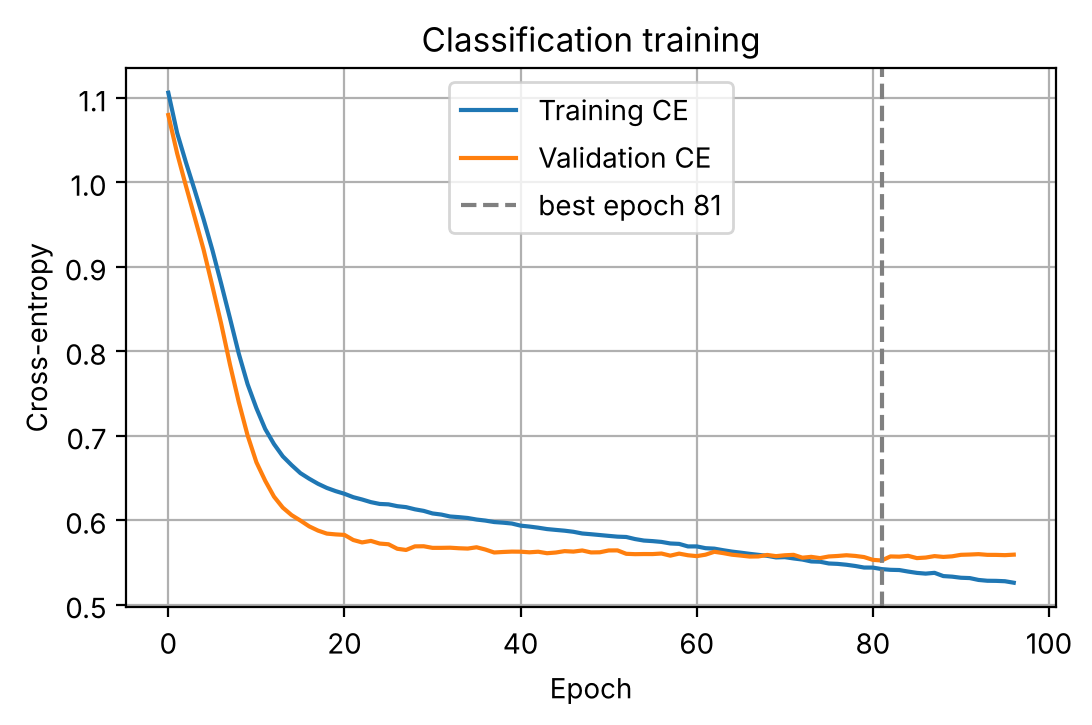

test CE 0.6524 | test accuracy 0.713
restored val loss equals best: True
predicted: [2, 0, 2, 1, 0, 1, 2, 2]
true     : [1, 0, 2, 1, 0, 1, 0, 2]


In [32]:
torch.manual_seed(1)
rng = np.random.default_rng(3)
# ---------- data: 3 overlapping clouds in 5-D, labels int64 ----------
n_per = 200
centers = np.array([[0, 0, 0, 0, 0], [2, 1, 0, -1, 0], [1, -2, 1, 1, 2]], dtype=np.float32)
Xc = np.concatenate([rng.normal(c, 1.6, size=(n_per, 5)) for c in centers]).astype(np.float32)
yc = np.repeat(np.arange(3), n_per).astype(np.int64)            # ORDERED by class -> must shuffle!
perm = rng.permutation(len(yc)); Xc, yc = Xc[perm], yc[perm]     # same perm for X and y

a, b = int(len(yc) * 0.5), int(len(yc) * 0.25)
Xc_tr, Xc_va, Xc_te = Xc[:a], Xc[a:a + b], Xc[a + b:]
yc_tr, yc_va, yc_te = yc[:a], yc[a:a + b], yc[a + b:]

cl_train_loader = DataLoader(TabularDataset(Xc_tr, yc_tr), batch_size=32, shuffle=True)
cl_val_loader   = DataLoader(TabularDataset(Xc_va, yc_va), batch_size=32, shuffle=True)
cl_test_loader  = DataLoader(TabularDataset(Xc_te, yc_te), batch_size=32, shuffle=False)

class ThreeClassNet(nn.Module):
    def __init__(self, n_in, k):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_in, 32), nn.ReLU(), nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, k))
    def forward(self, x):
        return self.layers(x)                                    # logits, no softmax

cl_model = ThreeClassNet(5, 3)
ce_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(cl_model.parameters(), lr=1e-3)

# ---------- training with early stopping ----------
max_epochs, patience = 500, 15
tr_hist, va_hist = [], []
best_val, best_state, best_epoch, bad_epochs = float('inf'), None, -1, 0
for epoch in range(max_epochs):
    tr_hist.append(run_epoch(cl_model, cl_train_loader, ce_fn, opt))   # run_epoch from Lesson 10
    va_hist.append(run_epoch(cl_model, cl_val_loader, ce_fn))
    if va_hist[-1] < best_val:
        best_val, best_epoch, bad_epochs = va_hist[-1], epoch, 0
        best_state = copy.deepcopy(cl_model.state_dict())
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"early stop at epoch {epoch}, best epoch {best_epoch} (val CE {best_val:.4f})")
            break
cl_model.load_state_dict(best_state)                              # restore best

plt.figure(figsize=(6, 3.5))
plt.plot(tr_hist, label='Training CE'); plt.plot(va_hist, label='Validation CE')
plt.axvline(best_epoch, color='gray', ls='--', label=f'best epoch {best_epoch}')
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.legend(); plt.grid(True); plt.title('Classification training'); plt.show()

# ---------- test CE + accuracy as python floats ----------
cl_model.eval()
with torch.no_grad():
    te_logits = cl_model(torch.tensor(Xc_te))
    te_targets = torch.tensor(yc_te)
example_test_ce = ce_fn(te_logits, te_targets).item()
example_test_acc = (te_logits.argmax(dim=1) == te_targets).float().mean().item()
print(f"test CE {example_test_ce:.4f} | test accuracy {example_test_acc:.3f}")
print("restored val loss equals best:", np.isclose(run_epoch(cl_model, cl_val_loader, ce_fn), best_val))

# ---------- a few predictions ----------
xb, yb = next(iter(cl_test_loader))
with torch.no_grad():
    pb = cl_model(xb).argmax(dim=1)
print("predicted:", pb[:8].tolist()); print("true     :", yb[:8].tolist())

#### 🏋️ Practice 13.1: early-stopping logic on a list

Write `simulate_early_stopping(val_losses, patience)` → `(best_epoch, last_epoch_run)`, using the **same logic** as above.
Going through the list is the "training". `last_epoch_run` = the epoch index where training stopped, or the last index if it never stopped.
- `[1.0, .8, .7, .72, .69, .71, .73, .74, .6]` with patience 3 → `(4, 7)`
- same list with patience 5 → `(8, 8)`

In [33]:
# ===== YOUR CODE BELOW =====
def simulate_early_stopping(val_losses, patience):
    raise NotImplementedError
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
L = [1.0, .8, .7, .72, .69, .71, .73, .74, .6]
check("13.1a", lambda: simulate_early_stopping(L, 3) == (4, 7))
check("13.1b", lambda: simulate_early_stopping(L, 5) == (8, 8))
check("13.1c", lambda: simulate_early_stopping([3, 2, 1], 1) == (2, 2))

⏳ 13.1a: not done yet
⏳ 13.1b: not done yet
⏳ 13.1c: not done yet


---
## Lesson 14: Confusion matrix (NumPy) + plot  (→ homework **I**)

`cm[i, j]` = number of samples whose **true** class is `i` and **predicted** class is `j`. Rows = true, columns = predicted. Correct predictions lie on the diagonal.

**Vectorized ways:**
```python
cm = np.zeros((k, k), dtype=np.int64)
np.add.at(cm, (y_true, y_pred), 1)                                   # 1) unbuffered add
cm = np.bincount(y_true * k + y_pred, minlength=k * k).reshape(k, k)  # 2) bincount trick (Week 6)
```
⚠️ **Trap:** `cm[y_true, y_pred] += 1` does **not** count duplicates. Each (i, j) pair gets +1 at most once.

**Plot requirements:** `imshow`, axis titles saying which axis is true and which is predicted, tick labels 0…k-1 on both axes, and the count written in every cell.

confusion matrix (rows=true, cols=pred):
 [[32 12  9]
 [10 38  4]
 [ 3  5 37]]
bincount way equal: True
diag / total = accuracy: 0.7133333333333334
the WRONG way (no duplicates counted):
 [[1 1 1]
 [1 1 1]
 [1 1 1]]


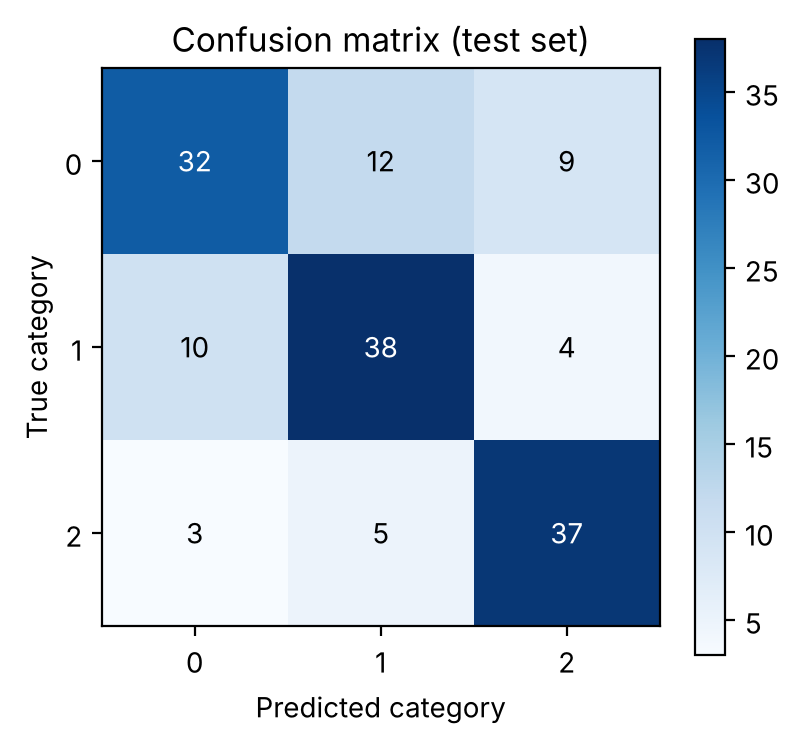

In [34]:
y_true_np = te_targets.numpy()
y_pred_np = te_logits.argmax(dim=1).numpy()
k = 3

cm = np.zeros((k, k), dtype=np.int64)
np.add.at(cm, (y_true_np, y_pred_np), 1)
print("confusion matrix (rows=true, cols=pred):\n", cm)
print("bincount way equal:", np.array_equal(cm, np.bincount(y_true_np * k + y_pred_np, minlength=k * k).reshape(k, k)))
print("diag / total = accuracy:", np.trace(cm) / cm.sum())

wrong = np.zeros((k, k), dtype=np.int64)
wrong[y_true_np, y_pred_np] += 1
print("the WRONG way (no duplicates counted):\n", wrong)

def plot_confusion(cm, title='Confusion matrix (test set)'):
    k = cm.shape[0]
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(cm, cmap='Blues')
    fig.colorbar(im, ax=ax)
    ax.set_xticks(range(k)); ax.set_yticks(range(k))
    ax.set_xlabel('Predicted category'); ax.set_ylabel('True category')
    for i in range(k):                     # text(x=column, y=row)
        for j in range(k):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_title(title)
    plt.show()

plot_confusion(cm)

#### 🏋️ Practice 14.1: confusion matrix with bincount

Write `confusion_np(y_true, y_pred, k)` using the **bincount** trick (no loops). It must work even if some class never appears.

In [35]:
# ===== YOUR CODE BELOW =====
def confusion_np(y_true, y_pred, k):
    raise NotImplementedError
# ===== YOUR CODE ABOVE =====

# ---- checker (don't edit) ----
check("14.1a", lambda: np.array_equal(confusion_np(np.array([0,0,1,2,2,2]), np.array([0,1,1,2,0,2]), 3),
                                       [[1,1,0],[0,1,0],[1,0,2]]))
check("14.1b (class 3 never appears)", lambda: np.array_equal(confusion_np(np.array([0,1]), np.array([1,1]), 4).shape, (4,4))
      and confusion_np(np.array([0,1]), np.array([1,1]), 4).sum() == 2)

⏳ 14.1a: not done yet
⏳ 14.1b (class 3 never appears): not done yet


---
## Lesson 15: Homework playbook (tomorrow's guide, task by task)

General rules: write only between `# implement your solution BELOW/ABOVE`, **keep the tester line**, use **vectorized** code, and turn final scores into Python floats (`.item()`).

| Task | What you produce | What the tester checks | Lessons | Traps |
|---|---|---|---|---|
| **A** | `dataset_noisy` from `content` | `np.ndarray`, **float32**, shape **(395, 33)**, 252 NaN, only in cols 8, 9, 11 | 2 | separator is `;` · skip header · skip the empty last line |
| **B** | `dataset` | float32, **(395, 36)**, no NaN, original values unchanged, last 3 columns only 0/1 | 3 | flags for cols **8, 9, 11 in this order**, **1 = present**, 0 = missing · flags **before** filling · `astype(np.float32)` |
| **C** | `dataset_split_train/val/test` | float32, 2-D, 36 cols, ≈197/99/99 rows, **order changed**, rows intact | 5 | shuffle **whole rows** · 50/25/25 · test = the rest |
| **D** | `dataloader_reg_train/val/test` | each batch `(x, y)`: float32, x `(B, 35)`, y **`(B, 1)`** | 8 | label = **col 32** kept 2-D (`[:, 32:33]`) · inputs = all other 35 cols (`np.delete`) · train/val `shuffle=True`, test `shuffle=False` |
| **E** | `reg_model` | parameter count of 35→25→25→1 | 9 | ReLU **between** layers, nothing after the last |
| **F** | trained model, plot, `test_mse` | `0.6 < test_mse < 3` | 6, 10 | MSE + Adam (lr 1e-3) · **no input scaling** · it needs many epochs (≈200–300) on this data, so pick the number from the val curve · legend + `ylim` · test MSE over the **full** test set as float · print a few pred vs true |
| **G** | `dataloader_cl_*` | x float32 `(B, 33)`, y **int64 `(B,)`** | 8, 11 | labels from G1, G2, G3 = **cols 30, 31, 32** with the priority rule (0 = "≥2 grades < 11", 1 = "mean < 14", else 2) · inputs = drop cols 30–32 → 33 cols · build labels in NumPy **per split** |
| **H** | `cl_model` | parameter count of 33→30→20→3 | 9, 12 | ReLU after the first two · last `Linear(20, 3)` with **no softmax** |
| **I** | trained model, plot, `test_ce`, `test_acc`, predictions, confusion matrix | `0.5 < test_ce < 1.2`, `0.5 < test_acc < 0.8` | 12, 13, 14 | `CrossEntropyLoss` · early stopping with `patience` (≈15–20) + **`deepcopy(state_dict())`** + `load_state_dict` after the loop · CE and accuracy as floats on the full test set · expect accuracy of only ≈0.55–0.65, which is normal here · confusion matrix plot with axis titles, ticks and counts |

**Suggested order tomorrow (≈4–5 h):** A→B→C (1 h) · D→E→F (1.5–2 h) · G→H→I (1.5–2 h). Copy the patterns from Lessons 2, 3, 5, 8, 10, 11, 13 and 14 and adapt the column indices and sizes.

---
## Lesson 16: Cheat sheet for the coding test

```python
# NumPy
np.isnan(a); np.count_nonzero(m, axis=0); np.any(m, axis=1); np.all(...)
np.nanmean / nanmax / nanmin / nansum
np.argmax(a, axis=1); np.argsort(a); np.sort(a, axis=0); np.unravel_index(i, a.shape)
a[np.arange(n), idx]            # one element per row
a[:, None]; a.reshape(-1, 1)    # (n,) -> (n,1)
x.mean(axis=0, keepdims=True)   # for broadcasting back
np.where(cond, x, y); np.where(mask)[0]; np.argwhere(mask)
np.concatenate([a, b], axis=1); np.column_stack([...]); np.stack([...], axis=1); np.delete(a, cols, axis=1)
np.eye(k)[labels]               # one-hot
np.bincount(ints, minlength=k); np.unique(a, return_counts=True)
rng = np.random.default_rng(0); rng.permutation(n)
np.select([c0, c1], [0, 1], default=2)

# PyTorch
torch.tensor(a, dtype=torch.float32 / torch.int64); t.item(); t.argmax(dim=1); torch.cat(list)
class M(nn.Module): __init__ (super().__init__(), layers) + forward(x)
nn.Linear(a, b) -> a*b + b params
nn.MSELoss() | nn.BCELoss() (+Sigmoid) | nn.CrossEntropyLoss() (logits, int64 targets (B,))
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
opt.zero_grad(); loss = fn(model(x), y); loss.backward(); opt.step()
model.train() / model.eval(); with torch.no_grad():
copy.deepcopy(model.state_dict()); model.load_state_dict(state)
Dataset (__len__, __getitem__) + DataLoader(ds, batch_size=32, shuffle=True)
```